---
## 1. Annotation
---
Currently, AI tools have become a real ubiquitous phenomenon, so many students use them for their studying or other purposes. In this project my aim is to examine the **impact of Generative AI** on student academic performance, mental health, and learning efficiency on students and learn the fundamentals of Python for data analysis, including working with **pandas**, **matplotlib**, and **seaborn** libraries.

The analysis is conducted on a **Kaggle** dataset **"AI Impact on Students"** containing **50000 observations** and **16 features**. The main objectives are to explore the data through descriptive statistics, create visualizations, perform data transformations, and test hypotheses about the relationships between AI usage patterns and student outcomes.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv("ai_student_impact_dataset.csv")
data.head(10)

---
## 2. Dataset Description
---
The dataset belongs to the field of **Educational Data Mining (EDM)** and **Learning Analytics**. It contains 50000 observations (rows) and 16 features (columns). Below is the detailed breakdown of all columns by their data types:
- **int64 (4):** Student_ID,  Tool_Diversity, Perceived_AI_Dependency, Anxiety_Level_During_Exams
- **float64 (4):** Pre_Semester_GPA, Weekly_GenAI_Hours, Traditional_Study_Hours, Post_Semester_GPA, Skill_Retention_Score
- **Str (6):** Major_Category, Year_of_Study, Primary_Use_Case, Prompt_Engineering_Skill, Institutional_Policy, Burnout_Risk_Level
- **Bool (1):** Paid_subscription


In [2]:
display(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  50000 non-null  int64  
 1   Major_Category              50000 non-null  str    
 2   Year_of_Study               50000 non-null  str    
 3   Pre_Semester_GPA            50000 non-null  float64
 4   Weekly_GenAI_Hours          50000 non-null  float64
 5   Primary_Use_Case            50000 non-null  str    
 6   Prompt_Engineering_Skill    50000 non-null  str    
 7   Tool_Diversity              50000 non-null  int64  
 8   Paid_Subscription           50000 non-null  bool   
 9   Traditional_Study_Hours     50000 non-null  float64
 10  Perceived_AI_Dependency     50000 non-null  int64  
 11  Institutional_Policy        50000 non-null  str    
 12  Anxiety_Level_During_Exams  50000 non-null  int64  
 13  Post_Semester_GPA           50000 non-null

None

**Data Quality:**
- No missing values (50000 non-null elements at each feature)
- Correct data types for all columns
- Consistent categorical values (no typos)

In [23]:
display(data.isna().sum().sum()) #number of missing values
display(data.isna().sum().sum() == 0, # Verify no missing values
        data["Pre_Semester_GPA"].dtype == float, # Verify expected dtype families
        data["Weekly_GenAI_Hours"].dtype == float,
        data["Paid_Subscription"].dtype == bool,
        set(data["Burnout_Risk_Level"].unique()) == {"High", "Medium", "Low"},# Verify categorical accuracy
        set(data["Institutional_Policy"].unique()) == {"Allowed_With_Citation", "Actively_Encouraged", "Strict_Ban"})

np.int64(0)

np.True_

True

True

True

True

True

The dataset is clean and requires no data cleaning operations. So the quality of data is very good.

---
## 3. Descriptive statistics
---
I chose features: Pre_Semester_GPA, Weekly_GenAI_Hours, Perceived_AI_Dependency, Anxiety_Level_During_Exams and Post_Semester_GPA - to calculate their minimal, maximum and mean value, median and standard deviation

In [4]:
# Pre Semester values:
display(data["Pre_Semester_GPA"].max(),
        data["Pre_Semester_GPA"].min(),
        data["Pre_Semester_GPA"].mean(),
        data["Pre_Semester_GPA"].median(),
        data["Pre_Semester_GPA"].std())


np.float64(3.998)

np.float64(1.183)

np.float64(3.14610234)

np.float64(3.21)

np.float64(0.4788543560796029)

In [5]:
display(data["Weekly_GenAI_Hours"].max(),
        data["Weekly_GenAI_Hours"].min(),
        data["Weekly_GenAI_Hours"].mean(),
        data["Weekly_GenAI_Hours"].median(),
        data["Weekly_GenAI_Hours"].std())

np.float64(40.0)

np.float64(0.0)

np.float64(8.4277522)

np.float64(5.8)

np.float64(8.269489724680797)

In [6]:
# Perceived AI Dependency values:
display(data["Perceived_AI_Dependency"].max(),
        data["Perceived_AI_Dependency"].min(),
        data["Perceived_AI_Dependency"].mean(),
        data["Perceived_AI_Dependency"].median(),
        data["Perceived_AI_Dependency"].std())

np.int64(10)

np.int64(1)

np.float64(3.50536)

np.float64(3.0)

np.float64(1.8208123400151788)

In [7]:
# Anxiety Level During Exams values:
display(data["Anxiety_Level_During_Exams"].max(),
        data["Anxiety_Level_During_Exams"].min(),
        data["Anxiety_Level_During_Exams"].mean(),
        data["Anxiety_Level_During_Exams"].median(),
        data["Anxiety_Level_During_Exams"].std())

np.int64(10)

np.int64(1)

np.float64(4.27076)

np.float64(4.0)

np.float64(2.144066454851448)

In [8]:
# Post Semester GPA values:
display(data["Post_Semester_GPA"].max(),
        data["Post_Semester_GPA"].min(),
        data["Post_Semester_GPA"].mean(),
        data["Post_Semester_GPA"].median(),
        data["Post_Semester_GPA"].std())

np.float64(4.0)

np.float64(1.0)

np.float64(3.3492994200000004)

np.float64(3.421)

np.float64(0.49567255190623366)

**Key observations:**
- The average Pre-Semester GPA is **3.15** (out of 4.0), and the Post-Semester GPA is slightly higher at **3.35**, suggesting an overall improvement during the semester.
- Weekly GenAI usage is highly spread out (std made up approximately **8.3** h), with some students using AI tools for 0 hours and others for up to 40 hours per week.

In [9]:
data.describe() #provides information about every numerical feature

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
count,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,125000.500000,3.146102,8.427752,2.80026,11.209271,3.505360,4.270760,3.349299,75.798125
std,14433.901067,0.478854,8.269490,1.18802,5.156426,1.820812,2.144066,0.495673,13.281626
min,100001.000000,1.183000,0.000000,1.00000,1.000000,1.000000,1.000000,1.000000,10.780000
25%,112500.750000,2.834000,2.390000,2.00000,7.560000,2.000000,3.000000,3.023750,66.820000
50%,125000.500000,3.210000,5.800000,3.00000,11.180000,3.000000,4.000000,3.421000,76.000000
75%,137500.250000,3.521000,11.720000,4.00000,14.710000,5.000000,6.000000,3.749000,85.190000
max,150000.000000,3.998000,40.000000,5.00000,35.860000,10.000000,10.000000,4.000000,100.000000


---
## 4. Data cleanup
---
As my data has been already clean, we would skip this part

---
## 5. Plots
---
1. Histogram: Weekly_GenAI_Hours
2. Box plot: Pre_Semester_GPA
3. Scatter plot: Weekly_GenAI_Hours vs Skill_Retention_Score
4. Pie chart: Major_Category

Text(0.5, 1.0, 'Major Category Distribution')

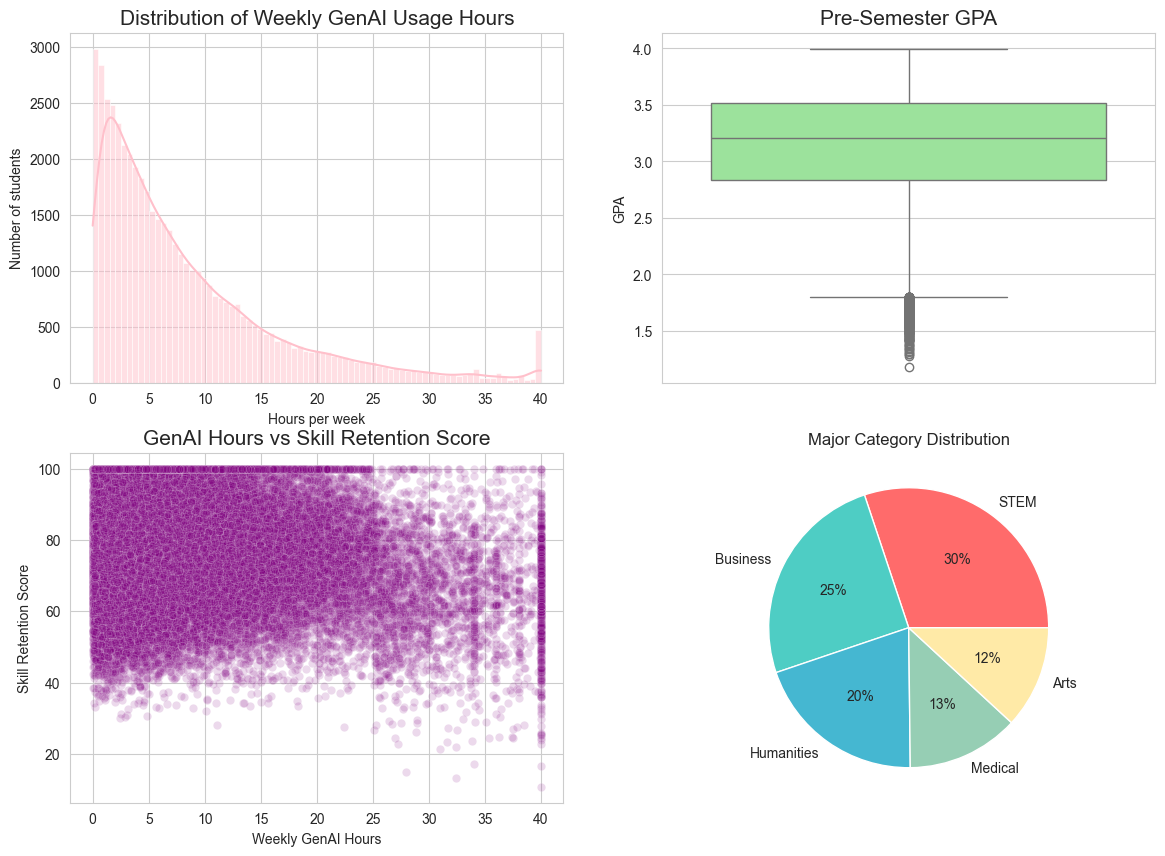

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Histogram: Weekly_GenAI_Hours
sns.histplot(data['Weekly_GenAI_Hours'], ax=axes[0,0],kde=True, color='pink')
axes[0,0].set_title('Distribution of Weekly GenAI Usage Hours', fontsize=15)
axes[0,0].set_xlabel('Hours per week')
axes[0,0].set_ylabel('Number of students')

# Box plot: Pre_Semester_GPA
sns.boxplot(y=data['Pre_Semester_GPA'], ax=axes[0,1], color='lightgreen')
axes[0,1].set_title('Pre-Semester GPA', fontsize=15)
axes[0,1].set_ylabel('GPA')

# Scatter plot: Weekly_GenAI_Hours vs Skill_Retention_Score
sns.scatterplot(x=data['Weekly_GenAI_Hours'], y=data['Skill_Retention_Score'], ax=axes[1,0], color='purple', alpha=0.15)
axes[1,0].set_title('GenAI Hours vs Skill Retention Score', fontsize=15)
axes[1,0].set_xlabel('Weekly GenAI Hours')
axes[1,0].set_ylabel('Skill Retention Score')

# Pie chart: Major_Category
category_counts = data['Major_Category'].value_counts()
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7']
axes[1,1].pie(category_counts, labels=category_counts.index, autopct='%1.0f%%', colors=colors)
axes[1,1].set_title('Major Category Distribution')


---
## 6. Detailed overview
---

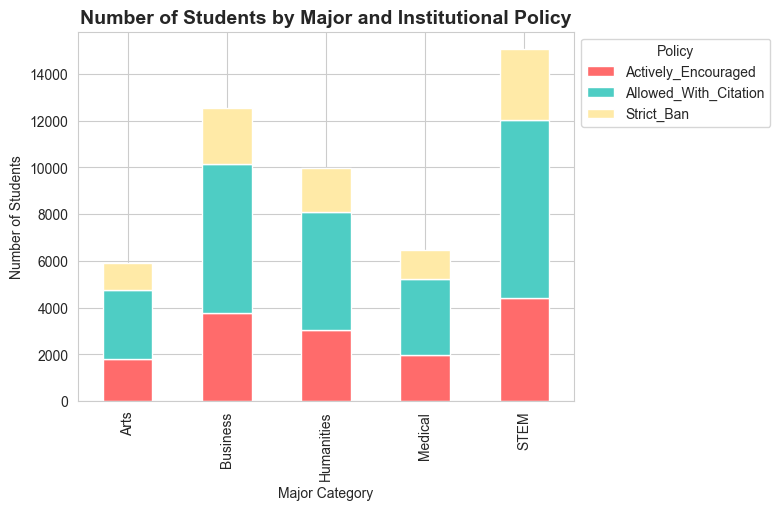

In [12]:
colors = ['#FF6B6B', '#4ECDC4', '#FFEAA7']
cross = data.groupby(["Major_Category","Institutional_Policy"]).size().unstack()
cross.plot(kind="bar", stacked=True, color=colors)
plt.title("Number of Students by Major and Institutional Policy", fontsize=14, fontweight="bold")
plt.xlabel("Major Category")
plt.ylabel("Number of Students")
plt.legend(title="Policy", bbox_to_anchor=(1, 1), loc="upper left")


The bars are almost equal in height across all majors, and the three policy colours are distributed evenly within each bar. This confirms that institutional policy is not connected to the student's choice of major — the distribution is essentially random

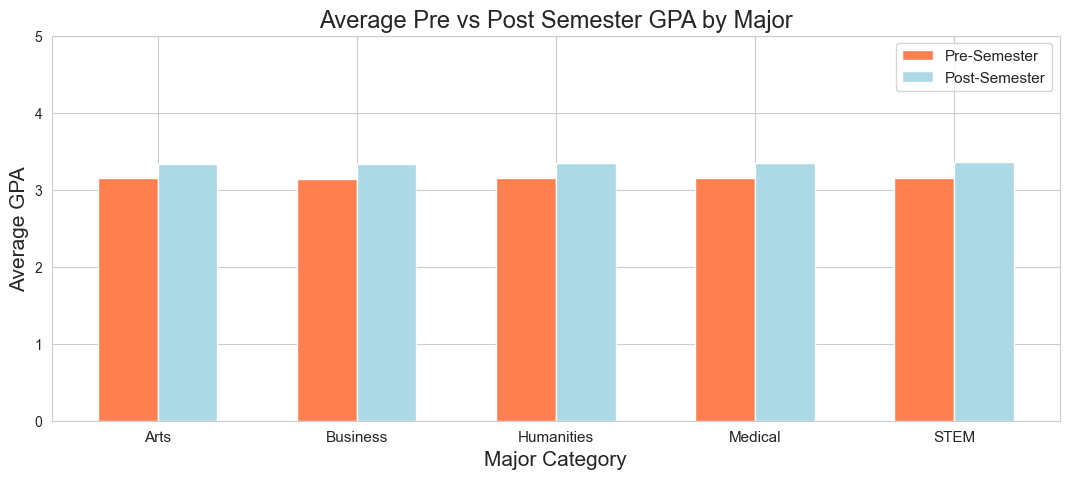

In [13]:
gpa_by_major = data.groupby("Major_Category")[["Pre_Semester_GPA","Post_Semester_GPA"]].mean().round(2)

fig, axes = plt.subplots(figsize=(13, 5))
x = range(len(gpa_by_major))
bars1  = axes.bar([i - 0.15 for i in x],gpa_by_major["Pre_Semester_GPA"], width=0.3, label="Pre-Semester", color="coral")
bars2  = axes.bar([i + 0.15 for i in x],gpa_by_major["Post_Semester_GPA"],width=0.3, label="Post-Semester", color="lightblue")

axes.set_xticks(list(x))
axes.set_xticklabels(gpa_by_major.index, fontsize=11)
axes.set_ylim(0, 5)
axes.set_title("Average Pre vs Post Semester GPA by Major", fontsize=17)
axes.set_xlabel("Major Category", fontsize=15)
axes.set_ylabel("Average GPA", fontsize=15)
axes.legend(fontsize=11)

Every major shows a GPA increase from pre- to post-semester, and the gap is very similar in all of them — around **+0.20 GPA points**. This tells us that the subject a student studies does not affect how much their grade changes during the semester. The improvement is the same for Business, Arts, Humanities, Medical, and STEM students.

Burnout_Risk_Level,High,Low,Medium
Year_of_Study,,,
Freshman,5.11,3.93,4.27
Sophomore,4.99,3.96,4.22
Junior,4.96,3.90,4.14
Senior,4.81,3.94,4.16
Graduate,4.66,3.87,4.04


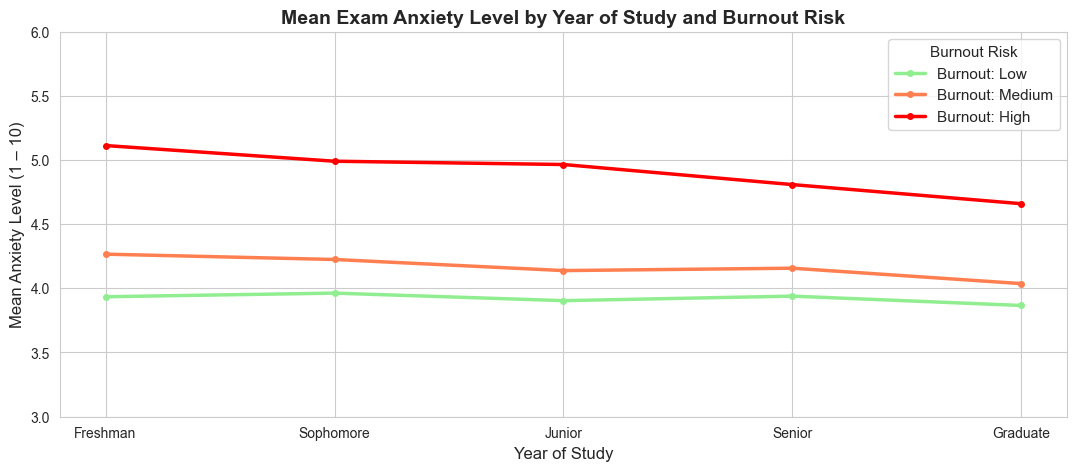

In [14]:
year_order   = ["Freshman", "Sophomore", "Junior", "Senior", "Graduate"]
burnout_colors = {"Low": "lightgreen", "Medium": "coral", "High": "red"}

anxiety_table = (data.groupby(["Year_of_Study", "Burnout_Risk_Level"])["Anxiety_Level_During_Exams"].mean().unstack().loc[year_order])

fig, ax = plt.subplots(figsize=(13, 5))
for level in ["Low", "Medium", "High"]:
    ax.plot(year_order, anxiety_table[level],
            marker=".", markersize=8, linewidth=2.5,
            color=burnout_colors[level], label=f"Burnout: {level}")

ax.set_title("Mean Exam Anxiety Level by Year of Study and Burnout Risk", fontsize=14, fontweight="bold")
ax.set_xlabel("Year of Study", fontsize=12)
ax.set_ylabel("Mean Anxiety Level (1 – 10)", fontsize=12)
ax.legend(title="Burnout Risk", fontsize=11, title_fontsize=11)
ax.set_ylim(3, 6)

display(anxiety_table.round(2))

The three lines are clearly separated across all five academic years. Students with high burnout risk report the most anxiety (around 6.4 around on average), while students with low burnout risk report the least (approximately 4.7). The lines stay parallel and flat across all years, which means anxiety levels do not change much as students progress from Freshman to Graduate. This shows that burnout risk is strongly linked to exam anxiety, but becoming more experienced does not seem to lower that anxiety.

(3.0, 4.688570896757114)

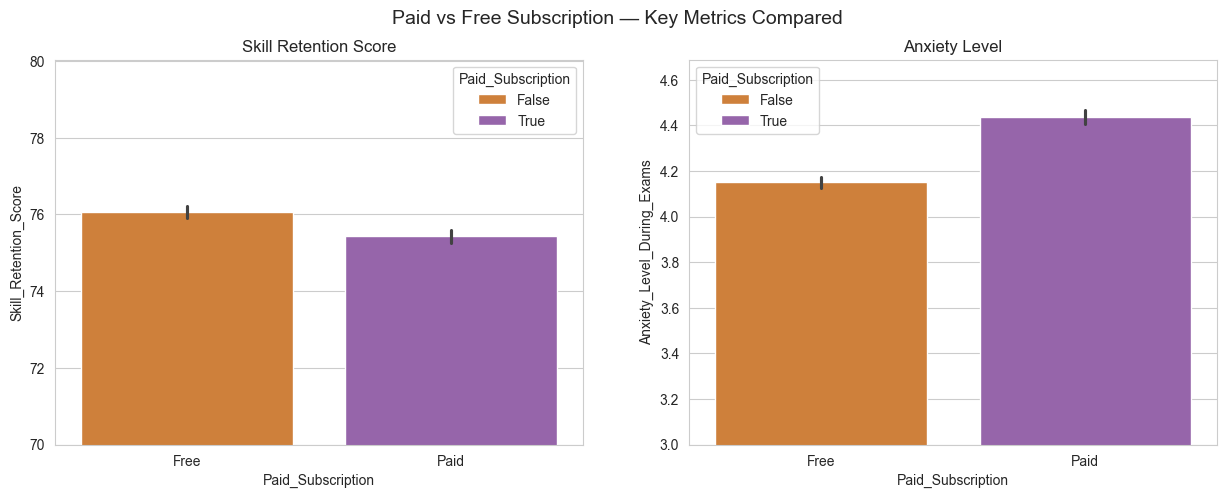

In [22]:
metrics = ['Skill_Retention_Score', 'Anxiety_Level_During_Exams']
titles = ['Skill Retention Score', 'Anxiety Level']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fig.suptitle('Paid vs Free Subscription — Key Metrics Compared', fontsize=14)

for ax, col, title in zip(axes, metrics, titles):
    sns.barplot(data=data, x='Paid_Subscription', y=col, hue='Paid_Subscription', palette=['#E67E22', '#9B59B6'], ax=ax)
    ax.set_title(title)
    ax.set_ylabel(col)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Free', 'Paid'])

axes[0].set_ylim(70)
axes[1].set_ylim(3)

In all three charts, the difference between the two groups is quite small. This strongly suggests that paying for an AI subscription does not give students a meaningful advantage in any of these areas.

## 7. Data transformation

Because the data required no cleanup, we add two new columns

In [42]:
# Column 1: GPA_Change
data["GPA_Change"] = data["Post_Semester_GPA"] - data["Pre_Semester_GPA"]

# Column 2: AI_Study_Ratio
total_hours = data["Weekly_GenAI_Hours"] + data["Traditional_Study_Hours"]
data["AI_Study_Ratio"] = (data["Weekly_GenAI_Hours"] / total_hours * 100)

data.head()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level,GPA_Change,AI_Study_Ratio
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High,-0.025,74.141221
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low,-0.125,6.302757
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium,0.101,67.257197
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium,0.211,10.674487
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium,0.163,42.536630


**GPA_Change** = `Post_Semester_GPA − Pre_Semester_GPA`. A positive value means the student improved; negative means decline

**AI_Study_Ratio** = `Weekly_GenAI_Hours / (Weekly_GenAI_Hours + Traditional_Study_Hours) × 100`. This captures the proportion of total study time dedicated to AI tools

## 8. Hypothesis check

## Hypothesis 1
**Students who spend more than 60% of their total study time on GenAI tools have lower Skill Retention Scores than students who spend less than 20%, and this pattern appears in both STEM and non-STEM majors**

In other words — if you use AI for most of your study time, you remember less. And this should be true no matter what subject you study.
We test this by splitting students into three groups based on their AI_Study_Ratio column, then comparing the average Skill Retention Score in each group. After that we check if the same pattern shows up separately for STEM and non-STEM students.

(65.0, 80.0)

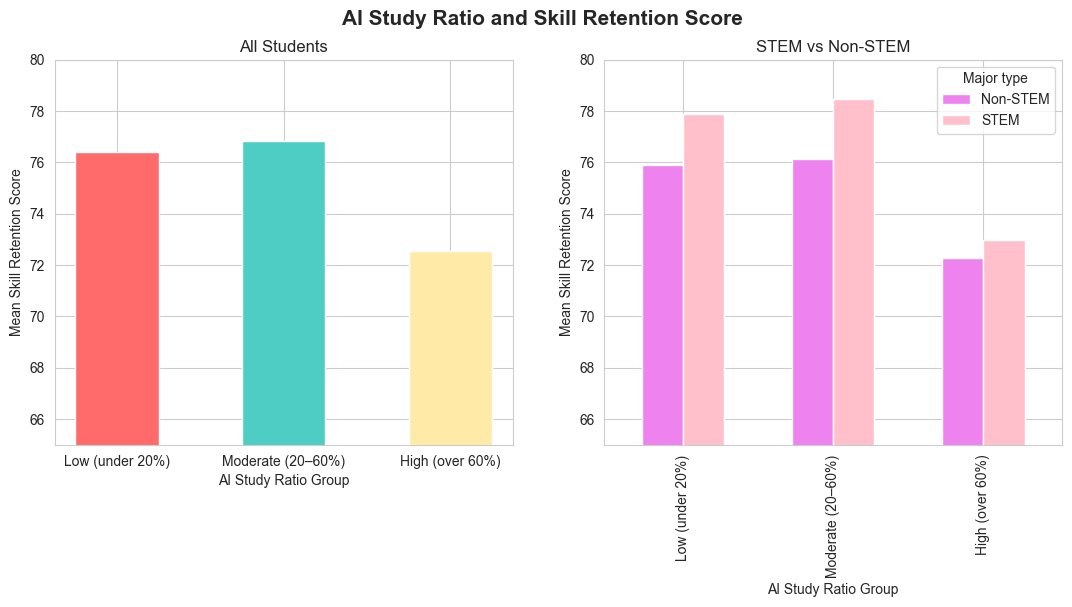

In [24]:
# Recreate AI_Study_Ratio in case it was not carried over from earlier cells
total_hours = data["Weekly_GenAI_Hours"] + data["Traditional_Study_Hours"]
data["AI_Study_Ratio"] = (data["Weekly_GenAI_Hours"] / total_hours * 100)
data["GPA_Change"] = data["Post_Semester_GPA"] - data["Pre_Semester_GPA"]

data["Ratio_Group"] = pd.cut(data["AI_Study_Ratio"], bins=[-1, 20, 60, 101],labels=["Low (under 20%)", "Moderate (20–60%)", "High (over 60%)"])

data["STEM_Flag"] = data["Major_Category"].apply(lambda x: "STEM" if x == "STEM" else "Non-STEM")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("AI Study Ratio and Skill Retention Score", fontsize=15, fontweight="bold")

colors = ['#FF6B6B', '#4ECDC4', '#FFEAA7']
order  = ["Low (under 20%)", "Moderate (20–60%)", "High (over 60%)"]

# Left plot —  bar chart for all students
means = data.groupby("Ratio_Group", observed=True)["Skill_Retention_Score"].mean().loc[order]
b = axes[0].bar(order, means, color=colors, edgecolor="white", width=0.5)
axes[0].set_title("All Students")
axes[0].set_xlabel("AI Study Ratio Group")
axes[0].set_ylabel("Mean Skill Retention Score")
axes[0].set_ylim(65, 80)

#grouped bar for STEM vs Non-STEM
pivot = (data.groupby(["STEM_Flag", "Ratio_Group"], observed=True)["Skill_Retention_Score"].mean().unstack())
pivot.T.plot(kind="bar",ax=axes[1],color={"STEM": "pink", "Non-STEM": "violet"},width=0.55,)
axes[1].set_title("STEM vs Non-STEM")
axes[1].set_xlabel("AI Study Ratio Group")
axes[1].set_ylabel("Mean Skill Retention Score")
axes[1].legend(title="Major type")
axes[1].set_ylim(65, 80)

In [22]:
print("Mean Skill Retention Score by AI Study Ratio Group:")
print(data.groupby("Ratio_Group", observed=True)["Skill_Retention_Score"].mean().round(2))
print()
print("Same thing, split into STEM and Non-STEM:")
print(data.groupby(["STEM_Flag", "Ratio_Group"], observed=True)["Skill_Retention_Score"].mean().round(2).unstack())

Mean Skill Retention Score by AI Study Ratio Group:
Ratio_Group
Low (under 20%)      76.39
Moderate (20–60%)    76.83
High (over 60%)      72.54
Name: Skill_Retention_Score, dtype: float64

Same thing, split into STEM and Non-STEM:
Ratio_Group  Low (under 20%)  Moderate (20–60%)  High (over 60%)
STEM_Flag                                                       
Non-STEM               75.91              76.15            72.26
STEM                   77.90              78.47            72.98


**Result:** Hypothesis 1 is confirmed

Students who spend less than 20% of their study time on AI tools have an average Skill Retention Score of **76.4**. Students who spend more than 60% score only **72.5** — that is about 4 points lower.

The right chart shows the same pattern for both STEM and non-STEM students. In both cases the green bar (low AI ratio) is the highest and the red bar (high AI ratio) is the lowest.

This means that using AI for most of your study time is connected to lower skill retention, no matter what subject you study.

## Hypothesis 2
 **Free subscription students who use many different AI tools (Tool_Diversity ≥ 4) have higher Skill Retention Scores and a bigger GPA improvement than paid subscription students who use only 1–2 tools. In other words, using AI in a wider variety of ways matters more than paying for a better tool**

We split students into two groups that are opposite in two ways at once — one group pays but uses few tools, the other does not pay but uses many tools. Then we compare both groups on two metrics: Skill Retention and GPA Change.

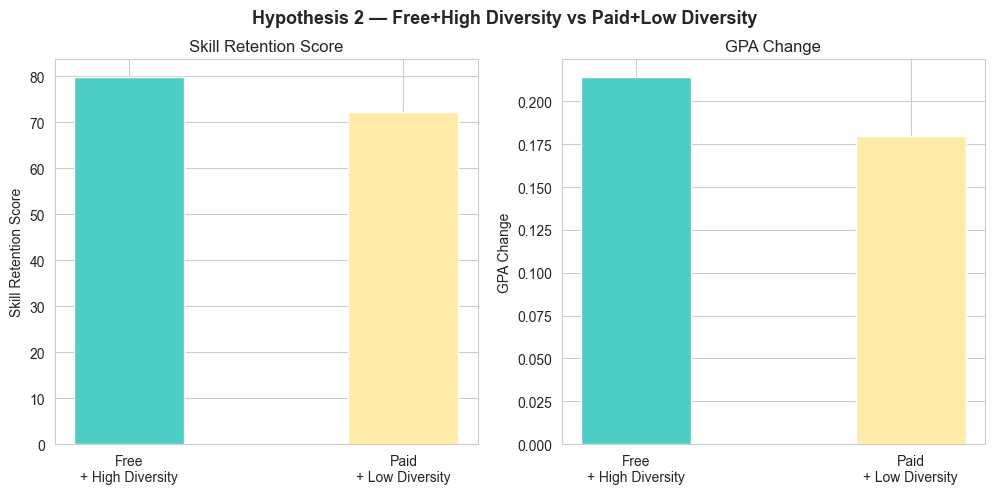

In [19]:
# Recreate AI_Study_Ratio in case it was not carried over from earlier cells
total_hours = data["Weekly_GenAI_Hours"] + data["Traditional_Study_Hours"]
data["AI_Study_Ratio"] = (data["Weekly_GenAI_Hours"] / total_hours * 100)
data["GPA_Change"] = data["Post_Semester_GPA"] - data["Pre_Semester_GPA"]

free_high = data[(data["Paid_Subscription"] == False) & (data["Tool_Diversity"] >= 4)]
paid_low  = data[(data["Paid_Subscription"] == True)  & (data["Tool_Diversity"] <= 2)]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Hypothesis 2 — Free+High Diversity vs Paid+Low Diversity", fontsize=13, fontweight="bold")

groups = ["Free\n+ High Diversity", "Paid\n+ Low Diversity"]
colors = ['#4ECDC4', '#FFEAA7']

for ax, (col, label) in zip(axes, [("Skill_Retention_Score", "Skill Retention Score"),("GPA_Change",            "GPA Change")]):
    vals = [free_high[col].mean(), paid_low[col].mean()]
    b = ax.bar(groups, vals, color=colors, edgecolor="white", width=0.4)
    ax.set_title(label)
    ax.set_ylabel(label)


In [ ]:
print(f"Free + High Diversity (≥ 4 tools):  {len(free_high):,} students")
print(f"Paid + Low Diversity  (≤ 2 tools):  {len(paid_low):,} students")
print()
print("Skill Retention Score:")
print(f"  Free + High Diversity: {free_high['Skill_Retention_Score'].mean():.1f}")
print(f"  Paid + Low Diversity:  {paid_low['Skill_Retention_Score'].mean():.1f}")
print()
print("GPA Change:")
print(f"  Free + High Diversity: {free_high['GPA_Change'].mean():.3f}")
print(f"  Paid + Low Diversity:  {paid_low['GPA_Change'].mean():.3f}")

**Result:** Hypothesis 2 is confirmed

Free + High Diversity students score **79.8** on Skill Retention, while Paid + Low Diversity students score only **72.3** — a difference of 7.5 points. The GPA Change is also higher for the free group (0.214 vs 0.180).

Both charts show the green bar clearly above the purple bar.

This is an interesting result: students who do not pay for AI but use many different tools get better outcomes than students who pay for a subscription but only use one or two tools. It shows that the variety of how you use AI is more important than how much you spend on it.